In [1]:
import sys, os, datetime, importlib

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import tqdm

import nn_reg; importlib.reload(nn_reg)
import nn_tf; importlib.reload(nn_tf)

<module 'nn_tf' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/nn_tf.py'>

/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/script_CoreExplorer.py:193: UserWarning: requested count 110000 exceeds dataset sample count 10300; retrieving 10300 samples.
  if (count > w_ind): warnings.warn(f'requested count {count} exceeds dataset sample count {w_ind}; retrieving {w_ind} samples.')


[22.19 28.16 34.5  41.36 49.04 58.17]


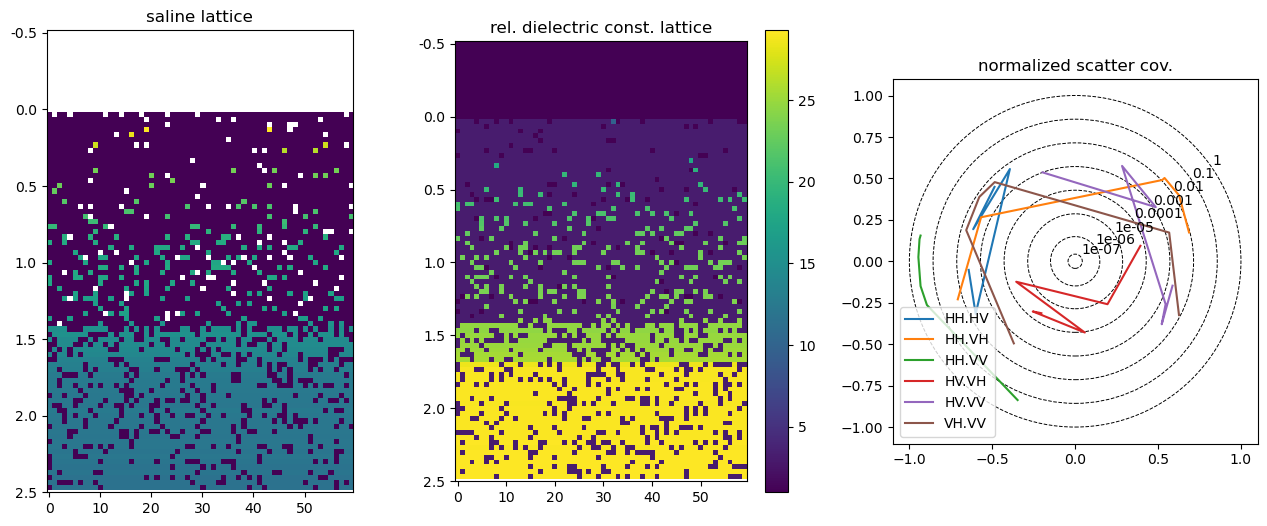

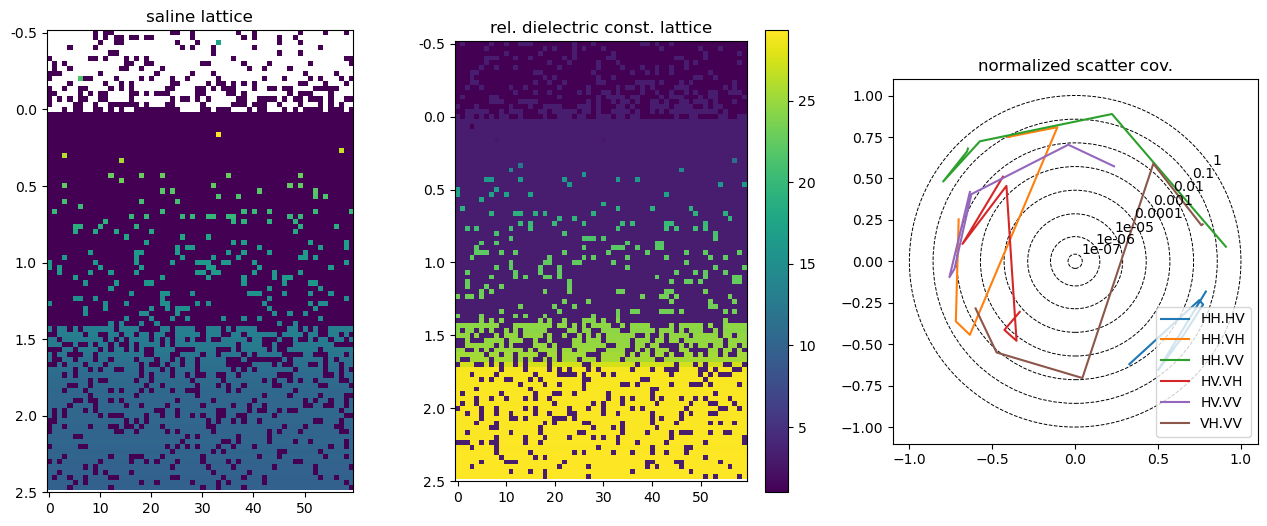

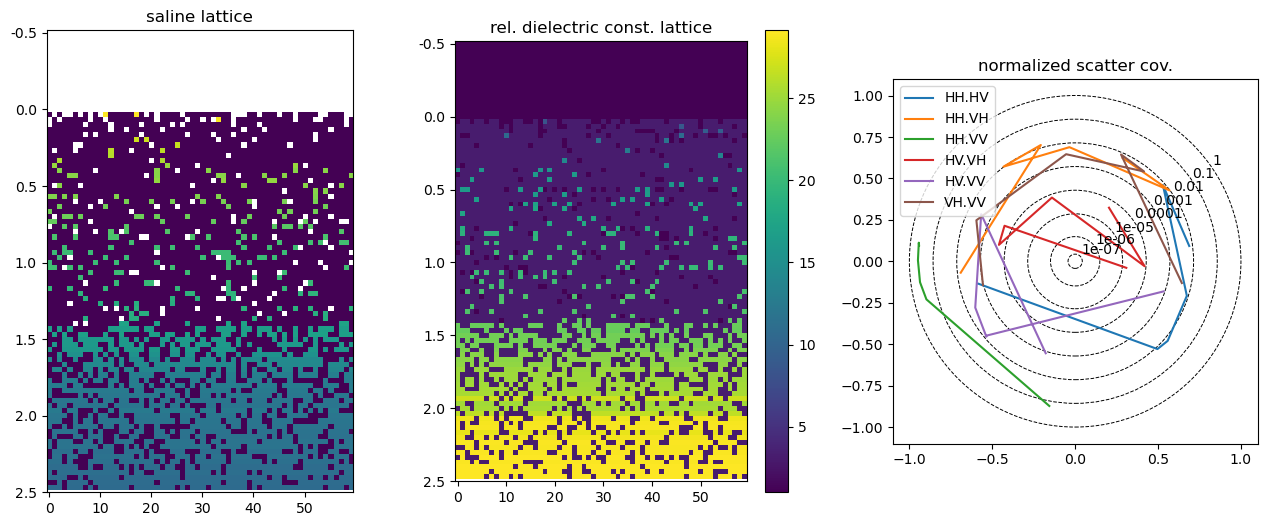

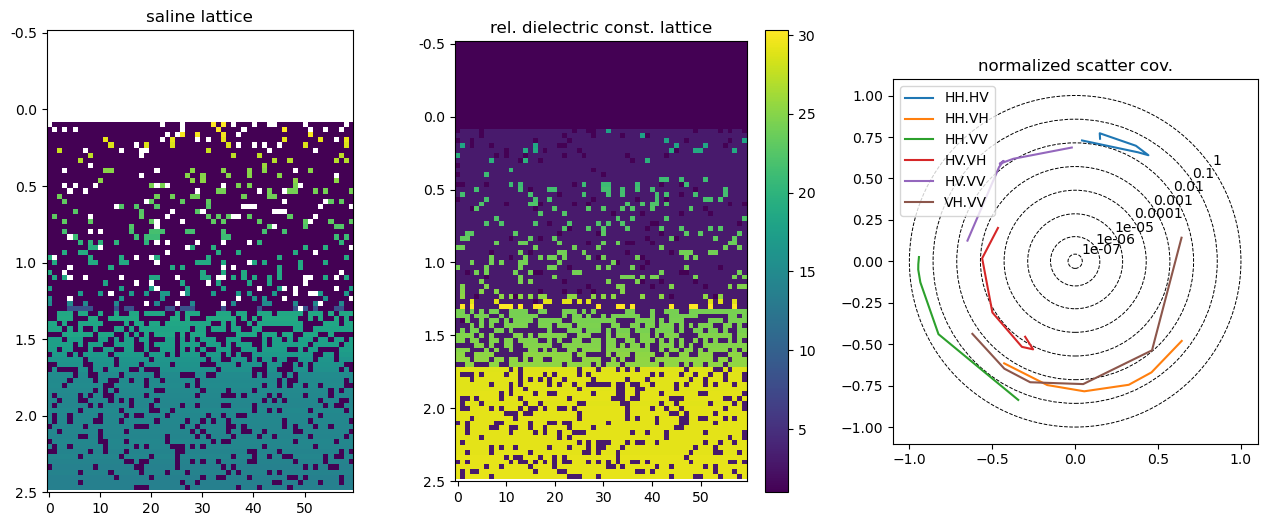

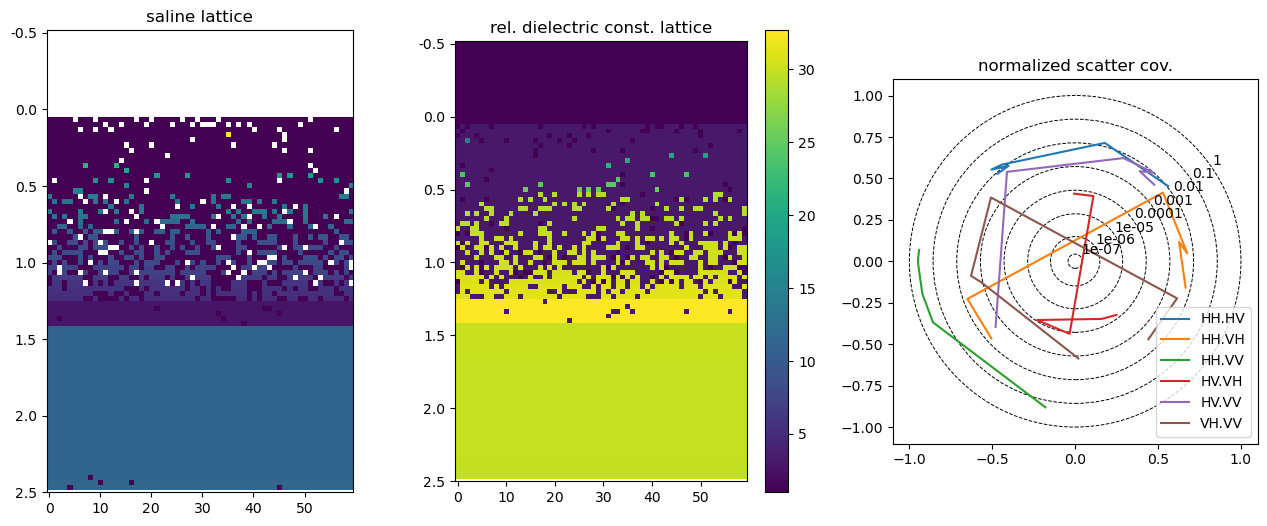

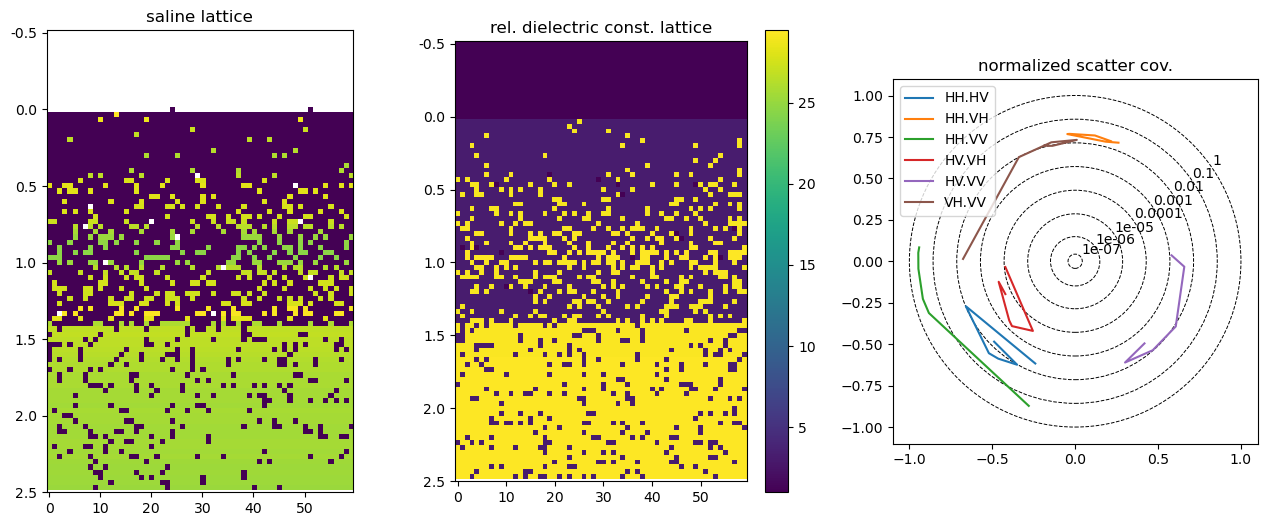

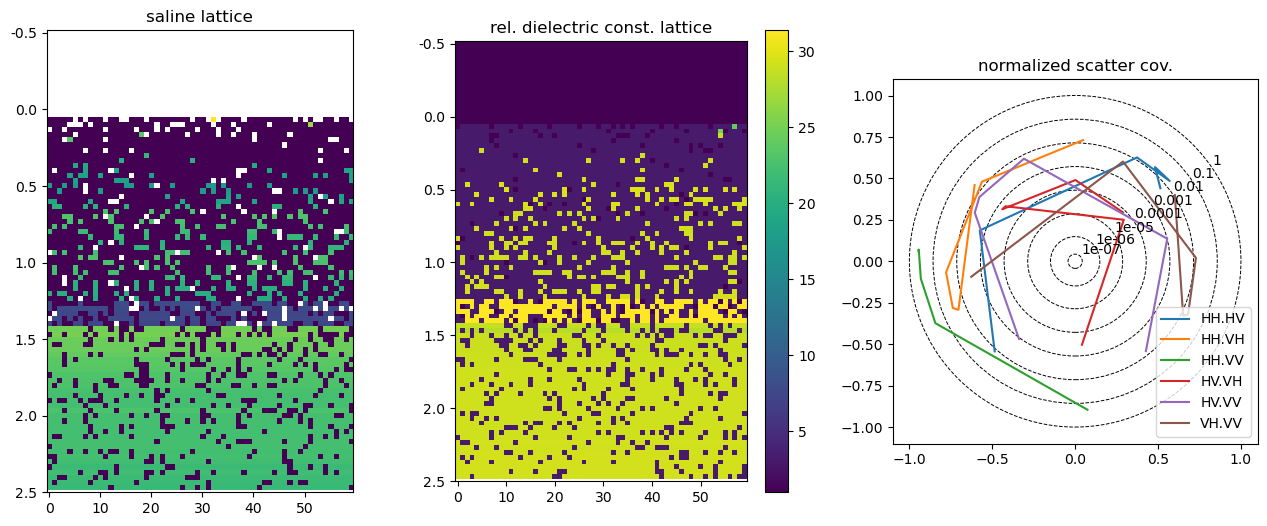

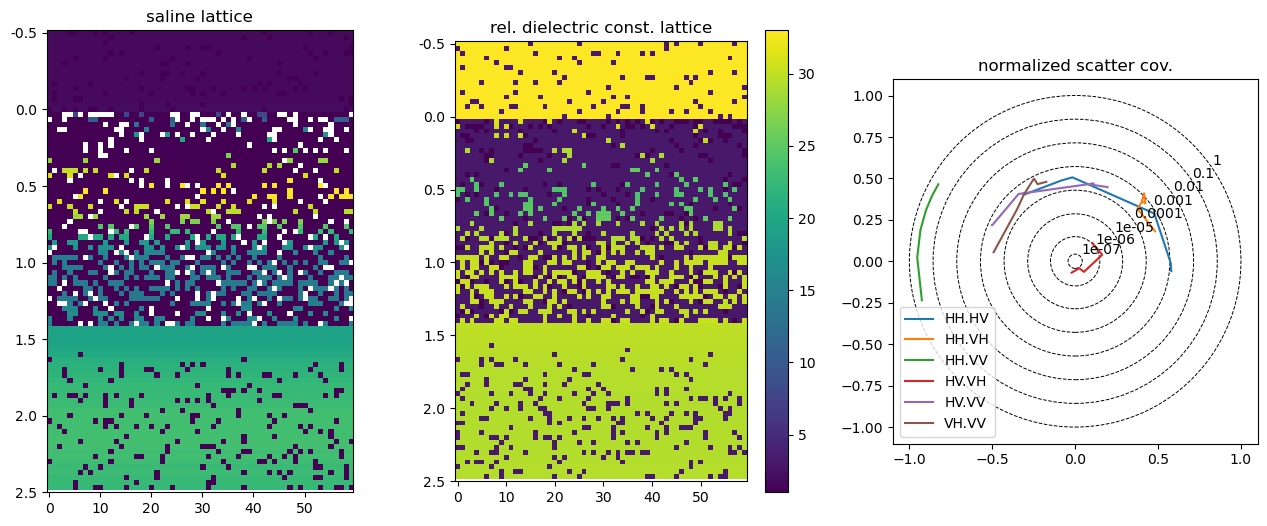

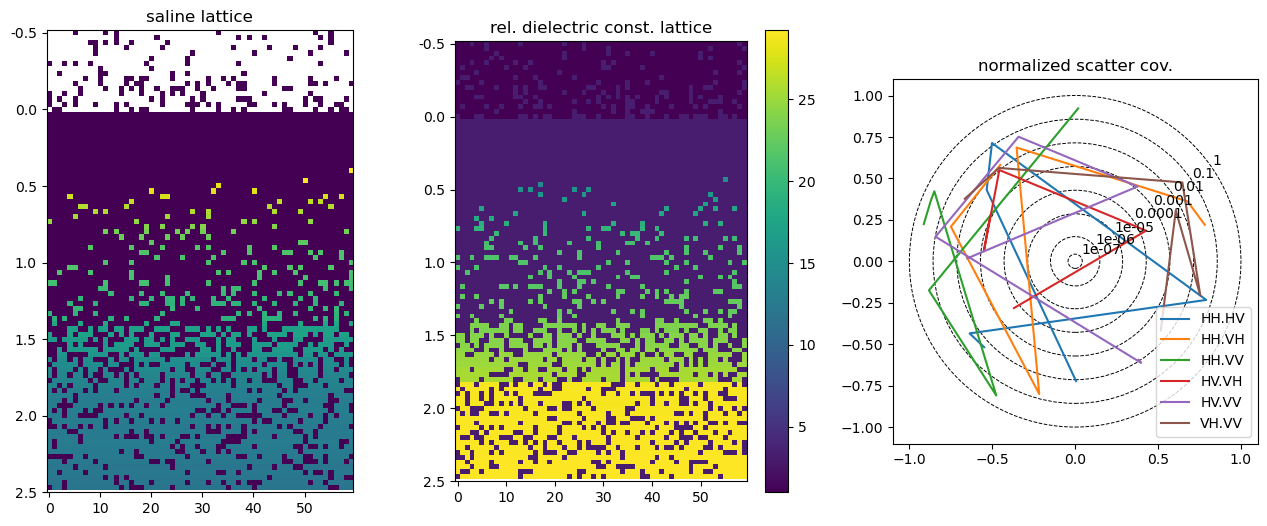

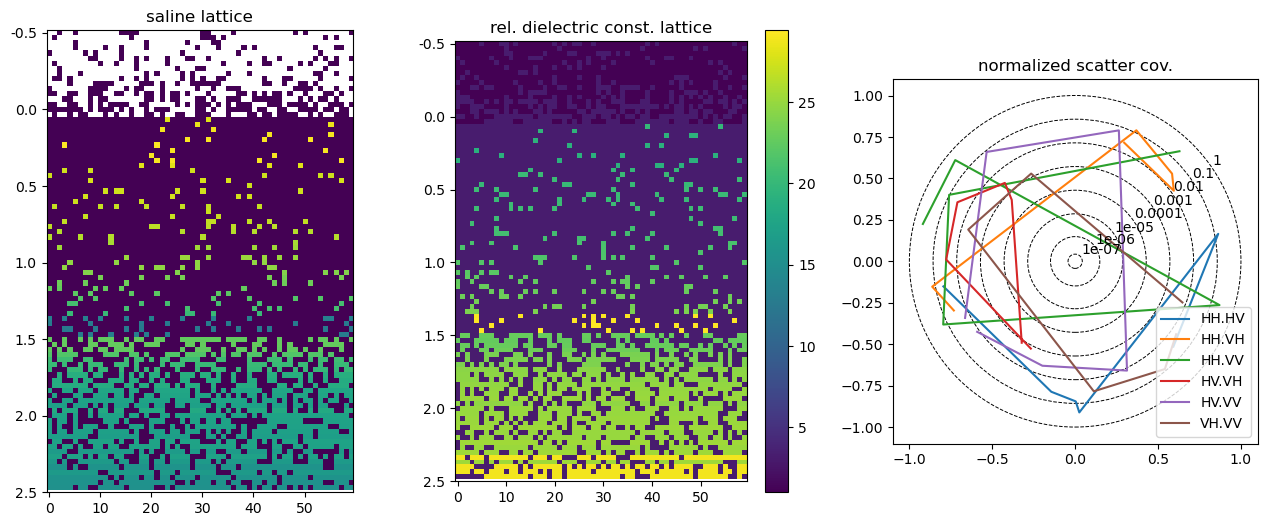

In [19]:
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import util_collector; importlib.reload(util_collector)
import util_metrics
from matplotlib.patches import Circle

whitener, dwhitenr = torch.nn.Identity(), torch.nn.Identity()
#whitener = nn_reg.FixedRescaler_mm(); dwhitenr = nn_reg.FixedDescaler_mm(whitener)
fn = 'em_resice_260922.hdf5'
#fn = 'em_resice.hdf5'
feed, floqs, vl, data_shapes = script_CoreExplorer.get_core(fn, 110000, whitener=whitener)
incidence_n = len(floqs); 

if True: # preview
    print(floqs)
    #for i in range(30,35):
    #    preview_feed = dwhitenr(feed)
    #    plt.figure(figsize=(10, 1.5))
    #    plt.subplot(1,3,1); plt.plot(preview_feed[i,0,:vl[0]].cpu()); plt.title('S')
    #    plt.subplot(1,3,2); plt.plot(preview_feed[i,0,vl[0]:vl[0]+vl[1]].cpu()); plt.title('T')
    #    plt.subplot(1,3,3); plt.plot(preview_feed[i,0,vl[0]+vl[1]:vl[0]+vl[1]+vl[2]].cpu()); plt.title('rho')
    #    plt.show()
    import brack2bing; icesim = brack2bing.LatticeSolver.load()
    closest = torch.argsort((feed[0,0,:270] - feed[:,0,:270]).abs().sum(dim=-1), dim=0)[:10]
    for i in closest:
        #plt.figure(figsize=(16,6))
        plt.figure(figsize=(16,6))
        S, T, rho = feed[i,0,:vl[0]], feed[i,0,vl[0]:vl[0]+vl[1]], feed[i,0,vl[0]+vl[1]:vl[0]+vl[1]+vl[2]]
        em_r, em_i = feed[i,0,-vl[-1]*2:-vl[-1]].view(6,16), feed[i,0,-vl[-1]:].view(6,16)
        em_r, em_i = em_r[:,[1,2,3,6,7,11]], em_i[:,[1,2,3,6,7,11]]
        bing = icesim.gen_lattice(T[None,],S[None,],rho[None,],(60,1)).cpu()[0,0,1:-1,1,1:-1].T;  bing[bing < 0] = torch.nan
        zing = icesim.get_dielectric(icesim.gen_lattice(T[None,],S[None,],rho[None,],(60,1)), T[None,], 0.236).real.cpu()[0,0,:,0].T
        #plt.subplot(3,3,1); plt.plot(S.cpu()); plt.title('S'); plt.xticks([])
        #plt.subplot(3,3,4); plt.plot(T.cpu()); plt.title('T'); plt.xticks([])
        #plt.subplot(3,3,7); plt.plot(rho.cpu()); plt.title('rho')
        #plt.xticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str)); plt.xlabel('depth (m)')
        plt.subplot(1,3,1); plt.imshow(bing); plt.title('saline lattice'); plt.yticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str))
        plt.subplot(1,3,2); plt.imshow(zing); plt.title('rel. dielectric const. lattice'); plt.yticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str)); plt.colorbar()
        plt.subplot(1,3,3)
        radii = 10**np.linspace(-7,0,8)
        transform = util_metrics.RadialLogTransform(scale=1/radii.min()) + plt.gca().transData
        plt.plot(em_r.cpu(), em_i.cpu(), transform=transform);
        for r in radii:
            r_t = transform.transform_non_affine([[r, 0]])[0, 0]
            plt.gca().add_patch(Circle((0, 0),r_t,transform=plt.gca().transData,fill=False,linestyle="--",linewidth=0.7))
            plt.text(r_t*np.cos(0.6), r_t*np.sin(0.6),f"{r:g}",transform=plt.gca().transData,ha="left",va="bottom")
        plt.gca().set_aspect("equal"); plt.title('normalized scatter cov.')
        plt.legend(['HH.HV','HH.VH','HH.VV','HV.VH','HV.VV','VH.VV'])
        plt.show()

In [16]:
16/3

5.333333333333333

In [3]:
feed.shape

torch.Size([10300, 1, 462])

In [383]:
import timewarp; importlib.reload(timewarp)
import nn_reg; importlib.reload(nn_reg)
import nn_tf; importlib.reload(nn_tf)

def calc_loss(x, y): # MSE & cosine loss
    bvar = 1e-6 + y.var(dim=0, keepdim=True)
    l_bcorr = ((x - y).pow(2) / bvar).mean() - F.cosine_similarity(x, y, dim=-1).mean()
    #xm, ym = x.mean(dim=0, keepdim=True), y.mean(dim=0, keepdim=True)
    #l_bcorr = ((x - y).pow(2) / bvar).mean() - F.cosine_similarity(x-xm, y-ym, dim=-1).sum(dim=-1).mean()
    #l_unscaled = (x - y).pow(2).mean() - F.cosine_similarity(x,y,dim=-1).mean()
    return l_bcorr

def get_condmask(x): # select & lock nC4 EM signature of 1 incidence in ...,EM_real,EM_imag feature vector
    _mask = torch.ones((x.shape[0], *data_shapes[-1]), device=x.device, dtype=torch.bool)
    k = torch.randint(incidence_n, (x.shape[0],), device=x.device)
    _mask[torch.arange(x.shape[0], device=x.device), :, k] = False # for (N,1,k,P,P)
    _mask = torch.cat([_mask.flatten(1), _mask.flatten(1)], dim=1)
    omask = torch.ones_like(x, dtype=torch.bool)
    omask[..., -_mask.shape[-1]:] = _mask[:,None,:] # transfer to full feature vector
    return omask


model = nn_tf.r2PA_Transformer(h=16, c=1, dim=feed.shape[-1], hdim=16, layers=4, activation='sigmoid')
wrapper = nn_reg.VMWrapper(model, feed.shape[-1], n=64, T=1).to('cuda', torch.float32)

# -- save whitener & dewhitener for later reference
model.whitener = whitener
model.unwhitener = dwhitenr

print('parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

parameters: 949112


In [ ]:
d_train, d_valid = feed[:-feed.shape[0]//10], feed[-feed.shape[0]//10:]
# optimizer
epochs, batch_size = 500, 1000
loss_hist = [0]
v_loss_hist = [0]
#opt = torch.optim.AdamW(wrapper.parameters(), lr=0.02, fused=True)
opt = torch.optim.AdamW(wrapper.parameters(), lr=0.005, fused=True)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=20, factor=0.9)
# iterated training
t_loop = tqdm.tqdm(range(epochs))
for i in t_loop:
    d_perm = torch.randperm(d_train.shape[0])
    for j in range(0, d_train.shape[0], batch_size):
        opt.zero_grad()
        s_train = d_train[d_perm[j:j+batch_size]]
        s_valid = d_valid[np.random.choice(np.arange(d_valid.shape[0]), size=batch_size)]
        loss    = wrapper.train(s_train)
        v_loss  = wrapper.train(s_valid, do_backprop=False).detach()
        opt.step()
        sched.step(v_loss)
        v_loss_hist.append(v_loss.item()); loss_hist.append(loss.detach().item())
        t_loop.set_description(f'epoch {i} - lr : {opt.param_groups[0]['lr']} - loss : {loss_hist[-1]}')
print(loss)

epoch 47 - lr : 0.003280500000000001 - loss : 1795.8154296875:   9%|█▌               | 47/500 [07:29<1:12:15,  9.57s/it]

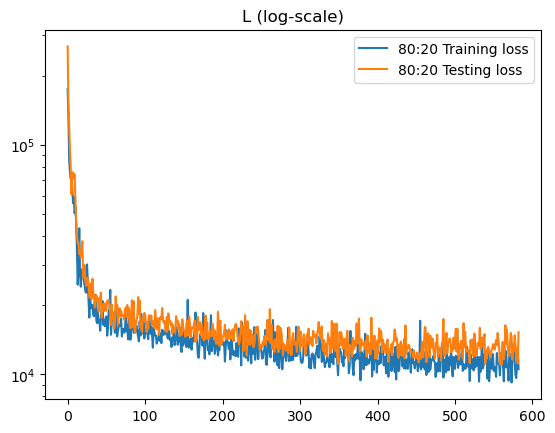

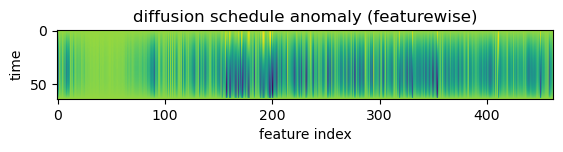

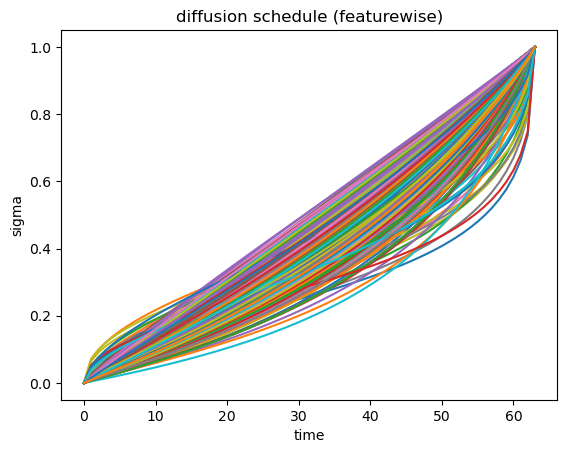

In [375]:
_st = 5
plt.plot(loss_hist[_st:]); plt.plot(v_loss_hist[_st:])
plt.legend(['80:20 Training loss', '80:20 Testing loss']);# plt.yscale('log')
plt.yscale('log'); plt.title('L (log-scale)')
plt.show()

sched = wrapper.schedf(torch.linspace(0,1,wrapper.n).to('cuda'), invert=True).detach().cpu()
plt.imshow(sched - torch.linspace(0,1,wrapper.n)[:,None]); plt.title('diffusion schedule anomaly (featurewise)')
plt.xlabel('feature index'); plt.ylabel('time'); plt.show()
plt.plot(sched); plt.title('diffusion schedule (featurewise)'); plt.xlabel('time'); plt.ylabel('sigma'); plt.show()

In [381]:
# visual examination corner
mmodel = wrapper.get_sampler()

#mmodel.T = 1

#mmodel = torch.load('260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth', weights_only=False)
#torch.save(mmodel, '261008_VelMatching_epoch500_t64_h16w16d4_RESICEAUG.pth')

#mmodel = torch.load('261007_VelMatching_epoch200_t32_h8w16d8_RESICEAUG.pth', weights_only=False)
#mmodel = torch.load('261008_VelMatching_epoch200_t32_h8w16d4_RESICEAUG.pth', weights_only=False)

mmodel.T = 10

index = 1000
count = 15

test = feed[index:index + count].clone()
truth_v = feed[index:index + count, -1]
test[...,:-16] = 0
view_shape = (count, -1)
mask_ = test != 0
result = test.clone()

with torch.no_grad():
    for i in range(1):
        result = mmodel(result, mask_)


result = (result.view(view_shape).detach())
test_v = test.view(view_shape)
def show(x): plt.plot(mmodel.net.unwhitener(x[None,None,:].detach()).cpu()[0,0,:]);
for i in range(0, len(result)):
    plt.figure(figsize=(6,2))
    show(test_v[i]); show(result[i]); show(truth_v[i]); plt.yscale('symlog')
    plt.legend(['input', 'generated', 'truth']); plt.title('conditional retrieval task: test simulated samples')
    plt.show()
# correlation graph
correl = (result.T @ truth_v / ((truth_v.T @ truth_v) * (result.T @ result))**0.5).detach().cpu().diagonal().numpy()
plt.plot(correl);
plt.title(f'viewed batch result:test correlations ({correl[np.isfinite(correl)].mean().astype(str)[:5]} average)'); plt.show()
#plt.figure(figsize=(9,2))
#plt.subplot(1,3,1); plt.plot(loss_hist[20:]); plt.title('training loss')
#plt.subplot(1,3,2); nn_util.visualize_scoremodel_density(model, feed.shape[-1])
#plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '261008_VelMatching_epoch1000_t32_h8w16d4_RESICEAUG.pth'

In [326]:
import PyPreprocess_Single
import script_CoreExplorer
import util_collector
import brack2bing; importlib.reload(brack2bing)
import os, math

retrieve = False
try: print(slc_ds.slc.shape)
except NameError:
    retrieve = True
if retrieve:
    slc_dir = '/mnt/d/ALOS1-Landfast/BeaufortSouth/'
    slc_fn = [el for el in os.listdir(slc_dir) if el[-4:] == '.zip'][15]
    cache_dir = slc_dir + slc_fn[:-4] + '_cache'
    slc_ds = PyPreprocess_Single.Dataset_SNAPbase(src_fn=slc_dir + slc_fn, cache_dir=cache_dir, read_nc=True, alos1_deskew=True)
    #slc_ds = PyPreprocess_Single.Dataset_SNAPbase.load_cache(cache_dir=cache_dir)
#slc, ia = slc_ds.slc[:,500:1500], slc_ds.ia[500:1500]
#slc, ia = slc_ds.slc, slc_ds.ia
slc, ia = slc_ds.slc[:,::8,::8], slc_ds.ia[::8,::8]

#filter_op = lambda x : F.avg_pool2d(torch.as_tensor(x[None,...]), 9, stride=1, padding=4, count_include_pad=False)[0]
#slc, ia = filter_op(slc.real) + 1j*filter_op(slc.imag), filter_op(ia[None,...])[0]

B,H,W = slc.shape
print(B, H, W)

icesim = brack2bing.LatticeSolver.load()
metric = torch.empty((H,W))

with torch.no_grad():
    stride = (50, 50)
    patches = ((i, j) for i in range(0, H, stride[0]) for j in range(0, W, stride[1]))
    for i, j in tqdm.tqdm(patches, total=((H+stride[0]-1)//stride[0] * (W+stride[1]-1)//stride[1])):
        slc_ = torch.as_tensor(slc[:, i:i+stride[0], j:j+stride[1]]).moveaxis(0,-1).cuda()
        ia_  = torch.as_tensor(ia[i:i+stride[0], j:j+stride[1]]).cuda()
        h, w = slc_.shape[0], slc_.shape[1]
        corevec, cond_mask = script_CoreExplorer.slc2core(slc_, ia_, sum(vl[:-2]), whitener, sim_inc=floqs)
        corevec = mmodel(corevec, cond_mask)
        TS = dwhitenr(corevec)[:,0,:sum(vl[:2])]
        S, T = TS[:,:vl[0]], TS[:,vl[1]:]
        core = icesim.get_icefrac(T, S).reshape(h,w,-1)
        ccore = core * ((core < 0.3).cumsum(dim=-1) == 0) # zero all entries after first melt-dominated layer in depth dim
        metric[i:i+h, j:j+w] = ccore.sum(-1).detach().cpu()


(4, 18432, 1248)
4 2304 156


 98%|███████████████████████████████████████████████████████████████████████████████▎ | 188/192 [00:23<00:00,  8.07it/s]


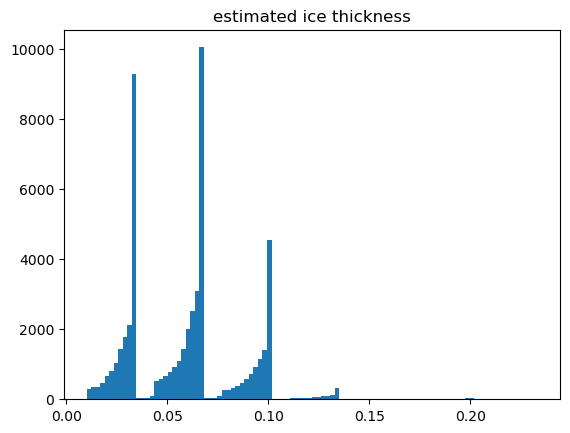

In [327]:
plt.hist(metric[(metric > 0) & (metric < 85)]/30, bins=100); plt.title('estimated ice thickness'); plt.show()
#plt.hist(metric.flatten(), bins=100); plt.show()
#plt.hist(metric.flatten()/30, bins=100); plt.show()
#metric.shape
#plt.plot(metric[100:,50:55]); plt.show()
#plt.plot(np.log1p(np.log1p(np.abs(slc[3,100:,50:55])))); plt.show()
#slc.shape

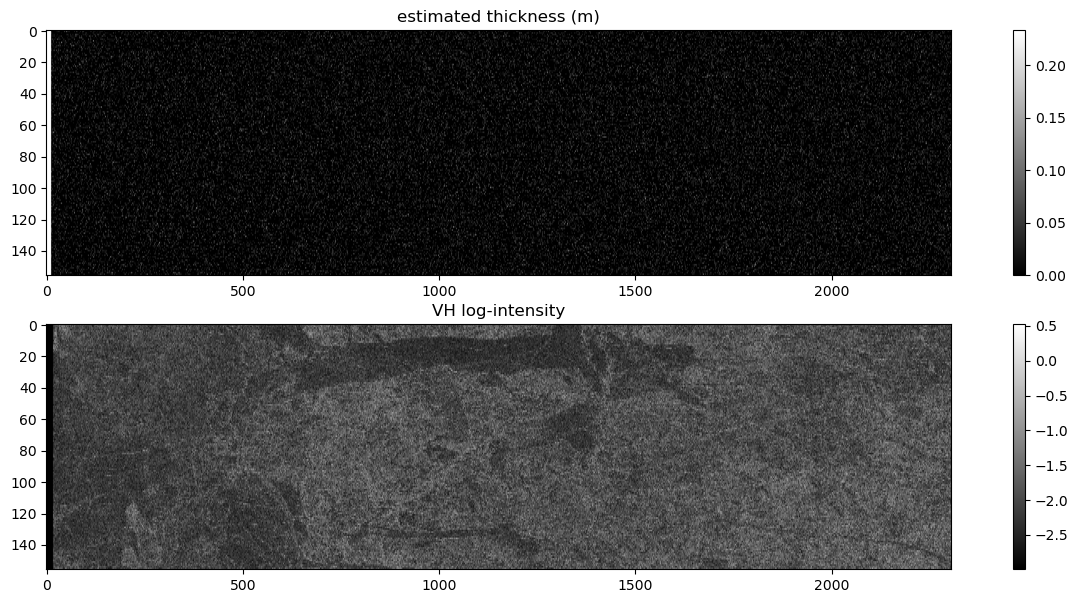

In [328]:
#gaussian = torch.exp(-torch.stack(tuple(torch.meshgrid(torch.linspace(-3,3,7), torch.linspace(-3,3,7), indexing='ij')),dim=-1).pow(2).sum(-1))
#gaussian /= gaussian.sum();  #tmp = F.avg_pool2d(tmp[None,None,], 5)[0,0]
#tmp = F.conv2d(metric[None,None,]/100, gaussian[None,None,], padding=3)[0,0]
look_metr = metric.clone()#.numpy()
#look_metr[look_metr > 80] = np.nan
#look_metr[look_metr > 0.5*30] = 0.5*30

#look_metr = torch.log1p(-F.max_pool2d(-look_metr[None,None,...], 3, 1, 1)[0,0]).numpy()
#look_metr = F.max_pool2d(look_metr[None,None,...], 5, 1, 2)[0,0]
#look_metr = look_metr * F.avg_pool2d(look_metr[None,None,...], 5, 1, 2)[0,0]

look_metr = look_metr / 30
look_metr[look_metr > 2.5] = np.nan
look_metr[look_metr < 0] = 0
plt.figure(figsize=(16, 7))
_aspect = 4

plt.subplot(2,1,1); plt.imshow(look_metr[:,:].T, cmap='gray', aspect=_aspect); plt.title('estimated thickness (m)'); plt.colorbar()
plt.subplot(2,1,2); plt.imshow(np.log(0.05+np.abs(slc[3, :, :].T)), cmap='gray', aspect=_aspect); plt.title('VH log-intensity'); plt.colorbar()
plt.show()

In [238]:
dlat, dlon = slc_ds.lat[::8,::8], slc_ds.lon[::8,::8]
image_date = int(datetime.datetime.fromtimestamp(slc_ds.metadata['0dopp_t0'][0]).strftime('%Y%m%d'))

import data_cryos; importlib.reload(data_cryos)

rdata = {}
for key in ['AMSR_KH','CS2','IC1','neXtSIM']:
    try: rdata[key] = data_cryos.get(key, image_date, dlat, dlon, mode='nearest')
    except: pass

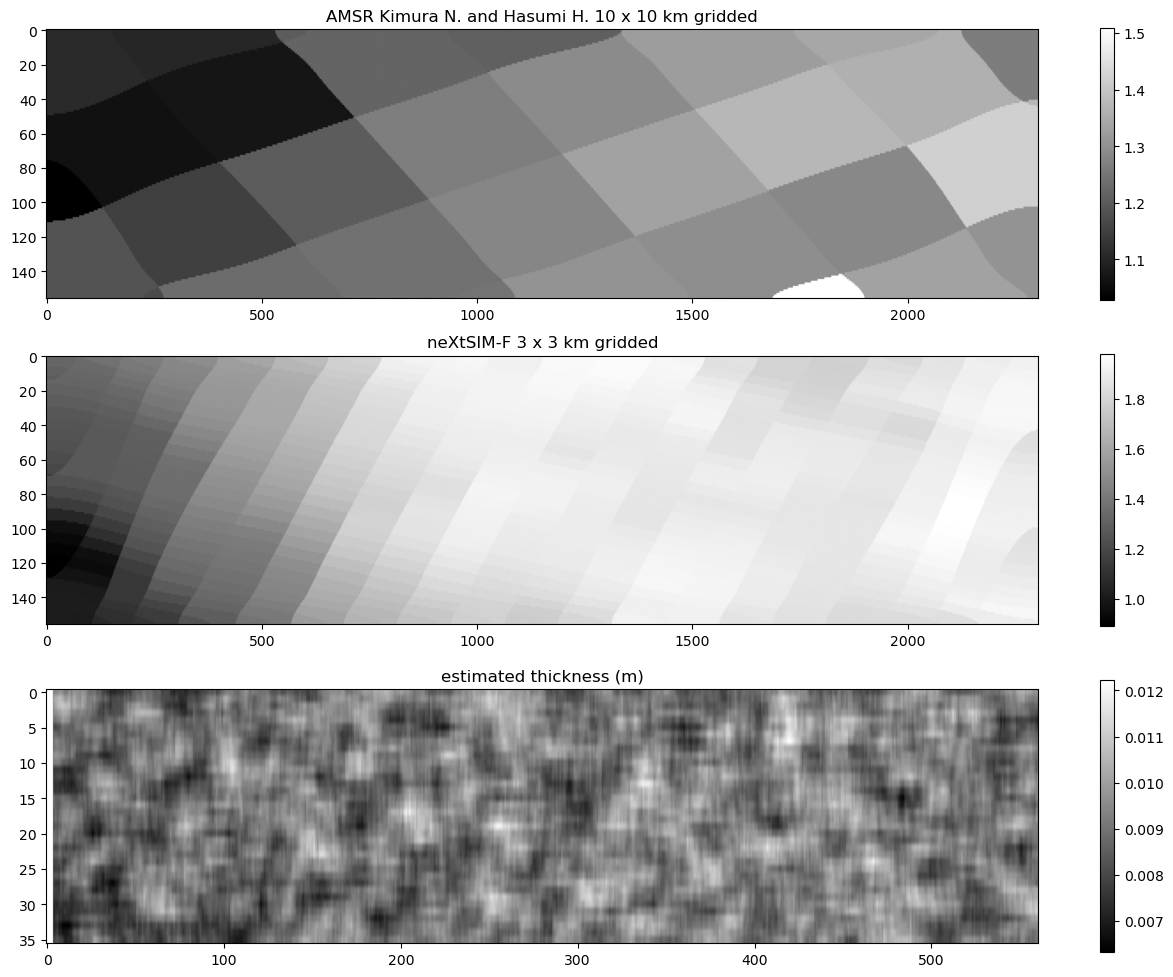

In [330]:
tmp_l = 1+len(rdata); plt.figure(figsize=(16, 4*tmp_l))
for i, (key, val) in enumerate(rdata.items()):
    plt.subplot(tmp_l, 1, i+1); plt.imshow(val.T, aspect=_aspect, cmap='gray');
    plt.title(data_cryos.TITLES[key]); plt.colorbar()
look_metr_downsamp = F.avg_pool2d(look_metr[None,None,], (32, 8), (4,4))[0,0]
plt.subplot(tmp_l,1,tmp_l); plt.imshow(look_metr_downsamp.T, aspect=_aspect, cmap='gray'); plt.title('estimated thickness (m)'); plt.colorbar()

In [1301]:

#Cmask = np.triu(np.ones((4,4))).astype(bool)
#Clabel = ('C' + np.arange(1,5)[None,:].astype(str) + np.arange(1,5)[:,None].astype(str))[Cmask]

#c4look = torch.as_tensor(slc[:,:,500]).permute(1,0)
#c4look = (c4look[:,None,:] * c4look[:,:,None].conj())[:,Cmask]

#plt.plot(c4look.abs()); plt.show()

#look = core * ((core == 0).cumsum(dim=-1) < 1)
#look = core
#plt.subplot(2,1,1); plt.plot(look.reshape(-1,look.shape[-1]).detach().cpu()[:20].T > 0.5); plt.title('ice fraction')
#plt.xticks(np.linspace(0,100,7), np.linspace(0,3,7)); plt.xlabel('metres')

# ...

#slc_ds = PyPreprocess_Single.Dataset_SNAPbase.load_cache(cache_dir='SNAPbase_latest_cache')
#slc_ds.ncWrite(metric.detach().cpu().numpy(), name='iceFrac')
'''import netCDF4
arr = metric.detach().cpu().numpy()
name = 'iceFrac'
ncd = netCDF4.Dataset(os.path.join(slc_ds.cache_dir, slc_ds.nc_fn), 'r+')
if name in ncd.variables.keys():
    ncd.variables[name][:] = arr
else :
    template_band = ncd.variables[[el for el in ncd.variables.keys() if 'i_' in el or 'q_' in el][0]]
    band = ncd.createVariable(name, template_band.datatype, template_band.dimensions)
    #band.setncatts(template_band.__dict__)
    band[:] = arr.astype(template_band.dtype)
ncd.close()'''